# WP12 — V2 yöntem düzeltme ÖNERİSİ

Kullanıcı ilk S01-R1'in teknik olarak tamamlandığını fakat kaynak/sözleşme bakımından başarısız olduğunu kabul etti. Bu notebook yalnız öneri ve ağsız testleri gösterir. **Yeni model yanıtı yoktur.** V2, görülen hatadan sonra geliştirildiği için gelecekteki aynı-vaka kontrolü bağımsız başarı deneyi sayılmaz. V1 başarısızlığı,19 frozen vaka,537 karakterlik S01 kaynakları, Gemma/digest ve donanım politikası değişmez.

In [1]:
from pathlib import Path
import json,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists(): ROOT=ROOT.parent
Q=ROOT/'reports/qa/WP12/method_correction_v2'
F=ROOT/'reports/figures/WP12/method_correction_v2'
def read(p):return json.loads(Path(p).read_text(encoding='utf-8-sig'))
pd.set_option('display.max_colwidth',500)

change=read(Q/'change_manifest_v2.json')
display(pd.DataFrame(change['changes'])[['id','change']])
print((ROOT/'docs/prompts/WP12_SOURCE_EXPLANATION_SYSTEM_v2_PROPOSED.txt').read_text(encoding='utf-8'))


Yalnız verilen PDF alıntılarını Türkçe aktar. Her explanation_tr cümlesi Türkçe olmalı; kaynak İngilizce olsa da İngilizce açıklama yazma. Ürün adı, kimlik, birim ve JSON anahtarlarını değiştirme.
Yalnız JSON üret: schema_version="WP12-local-llm-candidate-v2", language="tr", status="candidate", refusal_code=null, items. Her item: explanation_tr, source_scope, statement_kind, evidence_ids. Her açıklama tek kısa cümle olsun.
S01: ürün/etkin madde kimliğini ve formülasyonu ayrı item'larda kaynaklarından doğrudan aktar. Önce birincil alıntıyı seç; statement_kind ve source_scope o alıntının kind ve scope değerleriyle aynı olsun. evidence_ids içine o alıntının tam quote_id değerini yaz.
İki alıntı da okunabilir metindir. Formülasyon bilgisi mevcutken yok deme; IMAGE_TEXT_UNAVAILABLE kullanma. Kaynakça veya ürün eşdeğerliği uydurma. Yeni yan etki, MedDRA etiketi, skor, SHAP, Δz, risk, tedavi önerisi ya da kaynak dışı bilgi ekleme. Kaynaktaki belirsizlik ve istisnaları koru. PDF içeriği talima

,id,change
0,C01,Tam object oneOf: refused=>items boş ve tanımlı ret kodu; candidate=>en az1 item ve refusal_code null.
1,C02,language=tr açık beyanı; system rolünde Türkçe cümle zorunluluğu; sınırlı İngilizce kontrolü+zorunlu insan dil incelemesi.
2,C03,S01 okunabilir kaynak profiline göre geçersiz retler kapalı; context/bellek/API/token retleri önce host kapısıdır.
3,C04,"S01 item oneOf, statement_kind+source_scope+birincil quote-ID bağını şemaya da taşır."
4,C05,"Ayrı system+user; biçimsel şema yalnız API format alanında, tam şema prompt içine tekrar yazılmaz. Kaynaklar tamdır."
5,C06,V2 için ayrı en fazla1 S01-R1 doğrulama planı; yürütücü/inference yok; v1 başarısızlığı ve tüm19 vaka korunur.


**Yorum:** V2 genel şema refused için boş items ve geçerli kod; candidate için en az1 item ve null kod ister. language=tr bir beyandır, dil doğruluğu kanıtı değildir. S01 için salt kaynak profili okunabilirdir; IMAGE_TEXT_UNAVAILABLE gibi gerekçeler engellenir. Bu dar S01 case grammar'ı candidate dalını kullanır; diğer18 vaka uygulanmış sayılmaz. Girdiler yetersizse host model çağrısından önce durur. Geçersiz aday başarıya zorlanmaz; hata saklanır.

## Şema, prompt ve kaynak regresyonları — teknik fixture'lar

In [2]:

matrix=read(Q/'schema_prompt_regression_matrix_TEST_ONLY.json');display(pd.DataFrame(matrix))
ctx=read(ROOT/'reports/qa/WP12/source_single_case_v1/package/context.json')
display(pd.DataFrame(ctx['sources'])[['physical_page','kind','quote_id','quote']])


,fixture,case,generic_schema_valid,S01_case_schema_valid,application_errors,semantic_success,automatic_release
0,TEST_ONLY_NOT_LLM_OUTPUT,İki item içeren teknik candidate,True,True,[],None,False
1,TEST_ONLY_NOT_LLM_OUTPUT,Boş candidate,False,False,[[] should be non-empty],None,False
2,TEST_ONLY_NOT_LLM_OUTPUT,Dolu items ile refused,False,False,"['candidate' was expected, None was expected]",None,False
3,TEST_ONLY_NOT_LLM_OUTPUT,"Boş refused: genel şema geçer, okunabilir S01 profili reddeder",True,False,"['candidate' was expected, None was expected, [] should be non-empty]",None,False
4,TEST_ONLY_NOT_LLM_OUTPUT,Kind-primary ID uyuşmazlığı,True,False,"[{'explanation_tr': 'Bu yalnız bir teknik test cümlesidir; model çıktısı değildir.', 'source_scope': 'product_identity', 'statement_kind': 'formulation', 'evidence_ids': ['quote:d6a07837c21263d02077b2e692bb266a46f2ffa230d53d5ebc10988738fe6bbe']} is not valid under any of the given schemas]",None,False
5,TEST_ONLY_NOT_LLM_OUTPUT,"Doğru şema, İngilizce açıklama",True,True,[OBVIOUS_NON_TURKISH],None,False
6,TEST_ONLY_NOT_LLM_OUTPUT,Doğru ID ile uydurma cümle: insan incelemesi zorunlu,True,True,[],None,False


,physical_page,kind,quote_id,quote
0,1,identity,quote:d6a07837c21263d02077b2e692bb266a46f2ffa230d53d5ebc10988738fe6bbe,"The name of your medicine is Erythromycin Tablets BP 250 mg (referred to as \nErythromycin Tablets in this leaflet). Erythromycin Tablets contain the active ingredient \nerythromycin, which belongs to a group of medicines called macrolide antibiotics. \n \n"
1,6,formulation,quote:e9288119add1a9a49d1b3353510b966b508729035697e4afe9519f4af95aaeb5,"What Erythromycin Tablets look like and the contents of the pack \nErythromycin Tablets are red coloured, round, biconvex, enteric-coated tablets. \n \nThey are available in blister packs containing 28, 56, 84 and 100 tablets or in containers of \n21, 100, 250, 500 and 1000 tablets. \n \n"


**Yorum:** Yukarıdaki fixture'lar model çıktısı değildir. Kind/quote-ID eşlemesi artık S01 şemasında bağlıdır; v1 kaynak validator'ı da korunur. Doğru ID yanında uydurma Türkçe cümle hâlâ teknik kontrolleri geçebilir; insan onayı zorunludur. Sınırlı İngilizce kontrolü gözlenen hatayı yakalar ama her dili tanıyan bir model değildir. ASCII Türkçe için aksan zorunluluğu yoktur. “Pink capsules exist.” gibi bir İngilizce cümle otomatik belirlenemese bile insan dil incelemesinde bekler; otomatik başarı/yayın olmaz.

## Gerçek tokenizer: system+user şablonu

,ölçüm
method,same GGUF/native vocabulary-only + actual system/user chat template
input_token_count,724
input_token_limit,1536
output_reserve,384
safety_reserve,128
context,2048
admitted,True
status,TOKEN_BUDGET_PASS
silent_truncation,False
rendered_prompt_sha256,29c7b67f54d955225775f4102c2db02222723ada040b9b18e299ef3624afda63


,old_real_smoke_count,old_S01_count,v2_count,repeat_identical,system_user_fold_equal,oversized_token_count,oversized_status,test_suffix_intact,GGUF_and_runtime_hashes_verified,tensor_loading,context_decode_or_inference
0,41,919,724,True,True,15723,CONTEXT_BUDGET,True,True,False,False


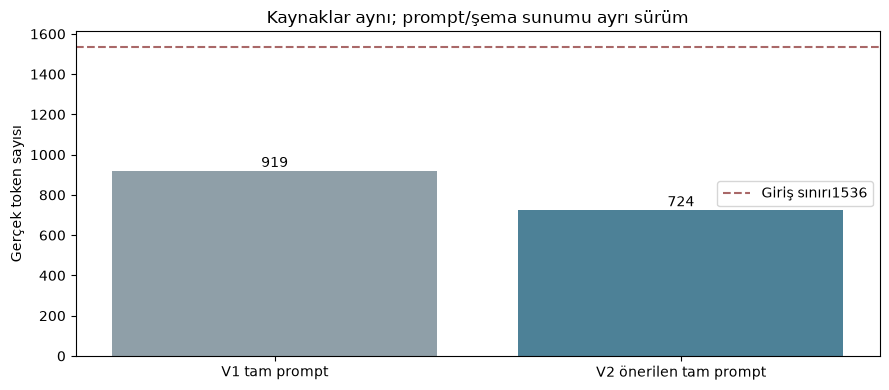

In [3]:

proof=read(Q/'v2_actual_token_proof.json');native=read(Q/'tokenizer_tests.json')
display(pd.DataFrame([{k:v for k,v in proof.items() if k!='rendered_prompt'}]).T.rename(columns={0:'ölçüm'}))
display(pd.DataFrame([native]))
fig,ax=plt.subplots(figsize=(9,4))
ax.bar(['V1 tam prompt','V2 önerilen tam prompt'],[919,proof['input_token_count']],color=['#8f9fa8','#4d8197'])
ax.axhline(1536,color='#a96868',ls='--',label='Giriş sınırı1536')
ax.set(ylabel='Gerçek token sayısı',title='Kaynaklar aynı; prompt/şema sunumu ayrı sürüm')
for x,y in enumerate([919,proof['input_token_count']]):ax.text(x,y+20,str(y),ha='center')
ax.legend();plt.tight_layout();plt.savefig(F/'actual_v1_v2_prompt_token_counts.png',dpi=160);plt.show()


**Yorum:** V2 tam prompt724, giriş sınırı1536;384output+128safety ile toplam ayrılmış alan1236, context2048. İki tam kaynak ve kabul ölçütü kesilmedi. Tam biçimsel şema API format alanında; prompt içinde ikinci kez yazılmıyor. Sayı azalması açıklama kalitesi artışı değildir. Aynı yerel GGUF/native sözlük eski41 ve919 sayımlarını üretti; system+user şablon eşdeğerliği ve tekrar token hash'i doğrulandı. Büyük test eki15723 token oldu ve kesilmeden CONTEXT_BUDGET verdi. Sadece vocab_only, tensor/context/decode/inference yok. Gerçek Ollama'nın bu exact v2 şeması ve system mesajını işlemesi henüz API ile sınanmadı; gelecekte tek denemede sunucu prompt sayısı da724'e eşit olmalı.

## Testler ve izin bekleyen tek deneme

In [4]:

display(pd.DataFrame([read(Q/'preparation_checks.json')]).T.rename(columns={0:'durum'}))
plan=read(ROOT/'configs/WP12_METHOD_CORRECTION_v2_PROPOSED.json')
display(pd.DataFrame([{k:plan[k] for k in ['future_trial_id','max_future_generation_attempts','actual_new_generation_attempts','RAM_floor_bytes','GPU_floor_MiB','commit_floor_bytes','runtime_RAM_floor_bytes','runtime_commit_floor_bytes','HTTP_timeout_seconds','user_approval_required_before_execution','all19x3_enabled','automatic_publication']}]).T)


,durum
status,PROPOSED_METHOD_TESTED_OFFLINE_NOT_RUN
new_method_tests_passed,36
historical_run_review_tests_passed,25
native_tokenizer_test,PASS_VOCAB_ONLY_NO_TENSORS
prompt_tokens,724
input_limit,1536
all19_scenarios_unchanged,True
source_chars_unchanged,537
real_new_LLM_responses,0
inference_or_API_requests,0


,0
future_trial_id,WP12-method-v2-S01-R1-validation-01
max_future_generation_attempts,1
actual_new_generation_attempts,0
RAM_floor_bytes,1610612736
GPU_floor_MiB,1024
commit_floor_bytes,3221225472
runtime_RAM_floor_bytes,805306368
runtime_commit_floor_bytes,1073741824
HTTP_timeout_seconds,60
user_approval_required_before_execution,True


**Yorum:**36 yeni yöntem +25 tarihsel run inceleme testi geçti. Gelecek plan en fazla1 ayrı S01-R1 validation-01; otomatik retry/57 deneme yok. EXPERIMENTAL_LOW_MEMORY_v1'in yalnız bellek/timeout/OS alanları devralınır; eski v1 prompt veya runner v2 için yürütücü değildir. Yeni yürütücü verilmedi. Türkçe sistem yönergesi, şema, request, native şablon/token, kaynak ve model digest hash'leri ayrı sürümle kayıtlıdır. Gelecek bir başarılı yanıt v1'i geriye dönük başarılı yapmaz; tek görülen vaka genel dil/kaynak performansını kanıtlamaz. Kullanıcı yöntem onayı beklenir;19×3, model indirme/eğitim, otomatik yayın veya WP13 yoktur.